# Projeto de Deep Learning — 06. Alerta por horizonte, viés de tempo

Os dois modelos finais (regressão logística e MLP) são **multiclasse**: 0 = não faliu no período observado;
$h$ = faliu no ano $h$ depois do balanço. Para cada empresa, o modelo dá $P(y=0), P(y=1), \dots, P(y=5)$, e a
probabilidade de falir em algum dos 5 anos é $1 - P(y = 0)$.

**Alerta precoce.** Somando as classes, o mesmo modelo dá a probabilidade de falir em até h anos, para h = 1 a 5.

**Viés de tempo.** O arquivo de origem não entra no modelo. Verificamos se isso distorce os resultados:
1. **detecção por ano verdadeiro**: recall a 5% de falsos positivos, separado pelo ano da falência;
2. **escore médio por classe verdadeira**: o modelo dá risco maior para quem quebra antes?
3. **taxa prevista por arquivo**: a probabilidade média prevista acompanha a taxa de falência de cada arquivo (de 3,9% a 7,0%)?


## Funções do projeto

As mesmas funções aparecem no início dos notebooks 03 a 06, para cada um rodar sozinho.

**Dados, pré-processamento e métricas.** Funções compartilhadas pelos notebooks 03, 04 e 05 (formulação multiclasse). Alvo multiclasse ---------------- Cada linha da base é um balanço. O arquivo `kyear.arff` traz balanços tirados (6 - k) anos antes do desfecho.   y = 0        se a empresa não faliu no período observado   y = h ∈ {1,…,5}   se a empresa faliu h anos depois daquele balanço (h = 6 - k) Interpretação: P(y = h) é a probabilidade de a empresa falir no ano h depois do balanço (ano exato). Cada ano é avaliado como um problema "um contra o resto". A pergunta "faliu em algum dos 5 anos?" usa 1 - P(y = 0). Pré-processamento: só os 63 indicadores originais (X37 descartado, ~44% de faltantes); faltantes imputados pela mediana do treino; nenhuma variável nova é criada. A redução de dimensão é obrigatória: filtro de correlação + VIF ou PCA, com cortes fixos. Suposição (limitação): as empresas ativas são tratadas como "não falha em nenhum horizonte", embora só se saiba que não faliram dentro do período observado (censura). O arquivo de origem NÃO entra como variável: para as falidas ele determina a classe (vazamento).

In [1]:
from pathlib import Path
import json
import os
import zipfile
import warnings

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
warnings.filterwarnings('ignore', message='.*physical cores.*')

import numpy as np
import pandas as pd
from scipy.io import arff

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import QuantileTransformer, RobustScaler, StandardScaler

set_config(transform_output='pandas')

RAPIDO = os.environ.get('RAPIDO') == '1'  # teste rápido do código (poucas configurações, poucas épocas)
SEMENTE = 42
N_FOLDS = 2 if RAPIDO else 5
REPETICOES = 2 if RAPIDO else 3   # repetições da CV (com outras divisões) na seleção robusta e nos testes
URL_DADOS = 'https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip'
FPR_ALVO = 0.05
CLASSES = [0, 1, 2, 3, 4, 5]
HORIZONTES = [1, 2, 3, 4, 5]
NOME_CLASSE = {0: 'não faliu', 1: 'faliu no ano 1', 2: 'faliu no ano 2', 3: 'faliu no ano 3',
               4: 'faliu no ano 4', 5: 'faliu no ano 5'}
VARS = [f'X{i}' for i in range(1, 65) if i != 37]  # X37 tem ~44% de faltantes (notebook 02)

ESCALAS = ['padronização', 'robusta', 'winsor + padronização', 'quantis (normal)']
SELECOES = ['corr + VIF', 'PCA 95%']  # redução obrigatória, cortes fixos (|r| > 0,8 e VIF ≥ 5; 95% da variância)
BALANCOS = ['nenhum', 'pesos', 'oversampling', 'SMOTE']

# Estilo dos gráficos (o mesmo dos notebooks anteriores)
TINTA, TINTA2, MUDO, GRADE, EIXO = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
ESTILO = {
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': EIXO, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUDO, 'ytick.color': MUDO, 'text.color': TINTA2, 'legend.frameon': False,
    'figure.dpi': 110, 'lines.linewidth': 2, 'font.size': 10,
}
COR = {'Regressão logística': '#2a78d6', 'MLP': '#eb6834'}
COR_H = dict(zip(HORIZONTES, ['#104281', '#1c5cab', '#2a78d6', '#5598e7', '#86b6ef']))


# ----------------------------------------------------------------------------------------------------------------
# Dados
# ----------------------------------------------------------------------------------------------------------------
def carregar(pasta='dados'):
    pasta = Path(pasta)
    arquivos = {k: pasta / f'{k}year.arff' for k in range(1, 6)}
    if not all(p.exists() for p in arquivos.values()):
        zip_ = pasta / 'polish+companies+bankruptcy+data.zip'
        if not zip_.exists():  # baixa da UCI na primeira execução
            import urllib.request
            pasta.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(URL_DADOS, zip_)
        with zipfile.ZipFile(zip_) as z:
            z.extractall(pasta)
    partes = []
    for k, p in arquivos.items():
        registros, _ = arff.loadarff(p)
        d = pd.DataFrame(registros)
        d.columns = [c.replace('Attr', 'X') for c in d.columns]
        d['class'] = d['class'].str.decode('utf-8').astype(int)
        partes.append(d.drop_duplicates().assign(arquivo=k))
    df = pd.concat(partes, ignore_index=True)
    df[VARS] = df[VARS].replace([np.inf, -np.inf], np.nan)
    df['y'] = np.where(df['class'] == 1, 6 - df['arquivo'], 0).astype(int)
    return df


def dividir(df, frac_teste=0.20):
    """Treino/teste estratificado pela classe multiclasse (que já inclui o horizonte das falidas)."""
    tr, te = train_test_split(df, test_size=frac_teste, stratify=df['y'], random_state=SEMENTE)
    return tr.reset_index(drop=True), te.reset_index(drop=True)


def folds(y, n=5, repeticao=0):
    """Folds estratificados da CV. repeticao = 0 é a divisão usada em todas as escolhas; repetições 1, 2, … sorteiam
    outras divisões (CV repetida), usadas só na seleção robusta e nos testes estatísticos."""
    return list(StratifiedKFold(n, shuffle=True, random_state=SEMENTE + repeticao).split(np.zeros(len(y)), y))


# ----------------------------------------------------------------------------------------------------------------
# Pré-processamento
# ----------------------------------------------------------------------------------------------------------------
class Winsorizador(BaseEstimator, TransformerMixin):
    """Corta cada coluna nos percentis [inferior, superior] aprendidos no fit."""

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior, self.superior = inferior, superior

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lim_inf_, self.lim_sup_ = X.quantile(self.inferior), X.quantile(self.superior)
        return self

    def transform(self, X):
        return pd.DataFrame(X).clip(self.lim_inf_, self.lim_sup_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.lim_inf_.index, dtype=object)


def vif(X):
    """VIF_j = j-ésimo elemento da diagonal da inversa da matriz de correlação (= 1 / (1 - R²_j))."""
    r = np.corrcoef(np.asarray(X, dtype=float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(r)), index=X.columns)


class FiltroCorrVIF(BaseEstimator, TransformerMixin):
    """Corte de correlação de Pearson (|r| > limiar_corr; fica a variável de maior |AUC - 0,5|) seguido de VIF
    iterativo (remove a de maior VIF até todas < limiar_vif). Mesmo critério do notebook 03 original."""

    def __init__(self, limiar_corr=0.80, limiar_vif=5.0):
        self.limiar_corr, self.limiar_vif = limiar_corr, limiar_vif

    def fit(self, X, y):
        X = pd.DataFrame(X)
        Xi = X.fillna(X.median())
        Xi = Xi.loc[:, Xi.std() > 0]
        yb = (np.asarray(y) > 0).astype(int)
        forca = pd.Series({c: abs(roc_auc_score(yb, Xi[c]) - 0.5) for c in Xi.columns}).sort_values(
            ascending=False, kind='stable')
        corr = Xi.corr().abs().fillna(0)
        mantidas, self.removidas_corr_ = [], {}
        for v in forca.index:
            conflito = [m for m in mantidas if corr.loc[v, m] > self.limiar_corr]
            if conflito:
                self.removidas_corr_[v] = conflito[0]
            else:
                mantidas.append(v)
        self.removidas_vif_ = []
        while len(mantidas) > 1:
            v = vif(Xi[mantidas])
            pior = v.idxmax()
            if v[pior] < self.limiar_vif:
                break
            self.removidas_vif_.append((pior, float(v[pior])))
            mantidas.remove(pior)
        self.colunas_ = mantidas
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.colunas_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colunas_, dtype=object)


def passos_preparo(escala, selecao):
    """Lista de passos (sklearn) para escala + seleção. Faltante → mediana do treino (sem criar colunas novas).

    'quantis (normal)': cada indicador é trocado pela sua posição (quantil) na distribuição do treino e depois levado
    à escala da normal padrão: x → Φ⁻¹(F̂(x)), onde F̂ é a distribuição acumulada empírica do treino (1000 quantis).
    Os valores extremos (±10⁶) viram no máximo ±5,2 e a ordem das empresas é preservada."""
    passos = []
    if escala == 'winsor + padronização':
        passos.append(('winsor', Winsorizador()))
    elif escala == 'quantis (normal)':
        passos.append(('quantis', QuantileTransformer(output_distribution='normal', n_quantiles=1000,
                                                      random_state=SEMENTE)))
    passos.append(('imput', SimpleImputer(strategy='median')))
    passos.append(('escala', RobustScaler() if escala == 'robusta' else StandardScaler()))
    if selecao == 'corr + VIF':
        passos.append(('selecao', FiltroCorrVIF()))
    elif selecao == 'PCA 95%':
        passos.append(('selecao', PCA(n_components=0.95, svd_solver='full', random_state=SEMENTE)))
    return passos


def amostrador(balanco, semente=SEMENTE):
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    if balanco == 'oversampling':
        return RandomOverSampler(random_state=semente)
    if balanco == 'SMOTE':
        return SMOTE(random_state=semente, k_neighbors=5)
    return None


def corrigir_priors(P, pi_treino, balanco):
    """Pesos de classe 'balanced', oversampling e SMOTE treinam como se as 6 classes tivessem a mesma frequência.
    Volta para a frequência real do treino (Saerens et al., 2002): p_k ∝ p̂_k · π_k / (1/6)."""
    if balanco == 'nenhum':
        return P
    P = P * (np.asarray(pi_treino) * len(CLASSES))
    return P / P.sum(axis=1, keepdims=True)


def priors(y):
    return np.bincount(np.asarray(y), minlength=len(CLASSES)) / len(y)


def pipeline_sklearn(escala, selecao, balanco, modelo):
    """Pipeline imblearn: o oversampling/SMOTE só é aplicado no fit (nunca nos dados de avaliação)."""
    from imblearn.pipeline import Pipeline
    passos = passos_preparo(escala, selecao) if escala is not None else (
        [('selecao', FiltroCorrVIF())] if selecao == 'corr + VIF' else [])
    am = amostrador(balanco)
    if am is not None:
        passos.append(('balanco', am))
    passos.append(('modelo', modelo))
    return Pipeline(passos)


def so_preparo(pipe):
    """Só os passos de pré-processamento de um pipeline (sem o amostrador e sem o modelo)."""
    from sklearn.pipeline import Pipeline
    passos = [(n, s) for n, s in pipe.steps if n not in ('balanco', 'modelo')]
    return Pipeline(passos) if passos else Pipeline([('nada', 'passthrough')])


def oof(fazer, balanco, X, y, divisoes, n_jobs=5):
    """Previsões fora da amostra (OOF) na CV: cada fold é ajustado só com os folds de treino.
    `fazer()` devolve um estimador novo; as probabilidades voltam para a frequência real das classes."""
    from joblib import Parallel, delayed
    y = np.asarray(y)

    def um(itr, iva):
        set_config(transform_output='pandas')
        m = fazer().fit(X.iloc[itr], y[itr])
        return iva, corrigir_priors(m.predict_proba(X.iloc[iva]), priors(y[itr]), balanco)

    P = np.zeros((len(y), len(CLASSES)))
    for iva, Pv in Parallel(n_jobs=n_jobs)(delayed(um)(itr, iva) for itr, iva in divisoes):
        P[iva] = Pv
    return P


# ----------------------------------------------------------------------------------------------------------------
# Métricas
# ----------------------------------------------------------------------------------------------------------------
def prob_ano(P, h):
    """P(falir no ano h depois do balanço) = P(y = h)."""
    return np.asarray(P)[:, h]


def rotulo_ano(y, h):
    return (np.asarray(y) == h).astype(int)


def prob_faliu(P):
    """P(falir em algum dos 5 anos) = 1 - P(y = 0)."""
    return 1 - np.asarray(P)[:, 0]


def recall_fpr(yb, s, alvo=FPR_ALVO):
    fpr, tpr, _ = roc_curve(yb, s)
    return tpr[fpr <= alvo].max()


def metricas(y, P):
    """Métricas do enunciado para cada ano exato da falência (classe h contra o resto) + médias + multiclasse.
    'PR-AUC média' (critério de escolha) = média da PR-AUC dos anos 1 a 5. 'faliu' = qualquer ano (1 - P(y=0))."""
    y, P = np.asarray(y), np.clip(np.asarray(P, dtype=float), 1e-12, 1)
    P = P / P.sum(axis=1, keepdims=True)
    out = {}
    for h in HORIZONTES:
        yb, s = rotulo_ano(y, h), prob_ano(P, h)
        out[f'PR-AUC ano {h}'] = average_precision_score(yb, s)
        out[f'ROC-AUC ano {h}'] = roc_auc_score(yb, s)
        out[f'Recall@FPR5% ano {h}'] = recall_fpr(yb, s)
    out['PR-AUC média'] = np.mean([out[f'PR-AUC ano {h}'] for h in HORIZONTES])
    out['ROC-AUC média'] = np.mean([out[f'ROC-AUC ano {h}'] for h in HORIZONTES])
    out['Recall@FPR5% médio'] = np.mean([out[f'Recall@FPR5% ano {h}'] for h in HORIZONTES])
    yb, s = (y > 0).astype(int), prob_faliu(P)
    out['PR-AUC faliu'] = average_precision_score(yb, s)
    out['ROC-AUC faliu'] = roc_auc_score(yb, s)
    out['Recall@FPR5% faliu'] = recall_fpr(yb, s)
    out['Log loss (multiclasse)'] = log_loss(y, P, labels=CLASSES)
    out['Brier (multiclasse)'] = float(np.mean(np.sum((P - np.eye(len(CLASSES))[y]) ** 2, axis=1)))
    return out


def metricas_cv(y, P_oof, divisoes):
    """Média e desvio-padrão entre folds das métricas, a partir das previsões fora da amostra (OOF)."""
    por_fold = pd.DataFrame([metricas(np.asarray(y)[iva], P_oof[iva]) for _, iva in divisoes])
    return por_fold.mean(), por_fold.std(ddof=1)


# ----------------------------------------------------------------------------------------------------------------
# Persistência dos resultados entre notebooks
# ----------------------------------------------------------------------------------------------------------------
PASTA_RES = Path('resultados')


def salvar_previsoes(nome, **arrays):
    PASTA_RES.mkdir(exist_ok=True)
    np.savez_compressed(PASTA_RES / f'prev_{nome}.npz', **arrays)


def carregar_previsoes(nome):
    with np.load(PASTA_RES / f'prev_{nome}.npz') as z:
        return {k: z[k] for k in z.files}


def salvar_json(nome, obj):
    PASTA_RES.mkdir(exist_ok=True)
    (PASTA_RES / f'{nome}.json').write_text(json.dumps(obj, ensure_ascii=False, indent=1, default=float), encoding='utf-8')


def carregar_json(nome):
    return json.loads((PASTA_RES / f'{nome}.json').read_text(encoding='utf-8'))

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline


warnings.filterwarnings('ignore')
plt.rcParams.update(ESTILO)
pd.set_option('display.width', 220)
df = carregar()
tr, te = dividir(df)
X_tr, y_tr = tr[VARS], tr['y'].values
X_te, y_te = te[VARS], te['y'].values
yb_te = (y_te > 0).astype(int)
CFG_LR = carregar_json('config_03')['Regressão logística']
MODELOS = ['Regressão logística', 'MLP']
PREV = {'Regressão logística': carregar_previsoes('logistica'), 'MLP': carregar_previsoes('mlp')}  # MLP final do notebook 04


def escores(m):
    """Escore de 'faliu' (qualquer ano) = 1 - P(y = 0), na validação (OOF) e no teste."""
    return 1 - PREV[m]['P_oof'][:, 0], 1 - PREV[m]['P_te'][:, 0]

## 1. Alerta precoce: probabilidade de falir em até $h$ anos

A tarefa pede a probabilidade de a empresa falir **dentro de um horizonte especificado**. O modelo multiclasse dá
isso sem novo treino, somando as classes:

$$P(\text{falir em até } h \text{ anos}) = P(y=1) + \dots + P(y=h), \qquad h = 1, \dots, 5.$$

Para cada $h$, o alvo é $1$ se $1 \le y \le h$ e $0$ caso contrário (inclui as que faliram depois de $h$ anos e as
que não faliram). Validação = previsões fora da amostra dos 5 folds; teste = 20% separados, com IC 95% por bootstrap
(1.000 reamostragens). O recall no teste usa o limiar que dá 5% de falsos positivos na validação.

In [3]:
DIV = folds(y_tr, N_FOLDS)
rng_b = np.random.default_rng(SEMENTE)
B = rng_b.integers(0, len(y_te), size=(100 if RAPIDO else 1000, len(y_te)))


def risco_ate(P, h):
    return P[:, 1:h + 1].sum(axis=1)


hor = []
for m in MODELOS:
    P_v, P_t = PREV[m]['P_oof'], PREV[m]['P_te']
    for h in HORIZONTES:
        a_v, a_t = ((y_tr >= 1) & (y_tr <= h)).astype(int), ((y_te >= 1) & (y_te <= h)).astype(int)
        s_v, s_t = risco_ate(P_v, h), risco_ate(P_t, h)
        pr_f = [average_precision_score(a_v[i], s_v[i]) for _, i in DIV]
        lim = np.quantile(s_v[a_v == 0], 1 - FPR_ALVO)
        boot = [average_precision_score(a_t[b], s_t[b]) for b in B]
        hor.append({'modelo': m, 'horizonte': f'até {h} ano(s)', 'prevalência teste': a_t.mean(),
                    'PR-AUC validação': np.mean(pr_f), 'dp validação': np.std(pr_f, ddof=1),
                    'PR-AUC teste': average_precision_score(a_t, s_t),
                    'IC inf': np.quantile(boot, 0.025), 'IC sup': np.quantile(boot, 0.975),
                    'ROC-AUC teste': roc_auc_score(a_t, s_t),
                    'recall a 5% FP (teste)': np.mean(s_t[a_t == 1] > lim),
                    'FP (teste)': np.mean(s_t[a_t == 0] > lim),
                    'prob. média prevista (teste)': s_t.mean()})
hor = pd.DataFrame(hor).set_index(['modelo', 'horizonte'])
hor.round(3)

prevalência teste  PR-AUC validação  dp validação  PR-AUC teste  IC inf  IC sup  ROC-AUC teste  recall a 5% FP (teste)  FP (teste)  prob. média prevista (teste)
modelo              horizonte                                                                                                                                                                     
Regressão logística até 1 ano(s)              0.010             0.094         0.052         0.103   0.065   0.179          0.839                   0.427       0.055                         0.010
                    até 2 ano(s)              0.022             0.133         0.025         0.135   0.101   0.189          0.800                   0.341       0.056                         0.022
                    até 3 ano(s)              0.033             0.167         0.019         0.161   0.130   0.207          0.799                   0.324       0.055                         0.034
                    até 4 ano(s)              0.042             0.183         0.013         0.189   0.155   0.230          0.789                   0.306       0.056                         0.043
                    até 5 ano(s)              0.048             0.196         0.015         0.208   0.174   0.249          0.780                   0.295       0.055                         0.049
MLP                 até 1 ano(s)              0.010             0.170         0.053         0.160   0.111   0.252          0.938                   0.610       0.049                         0.010
                    até 2 ano(s)              0.022             0.298         0.033         0.287   0.232   0.360          0.925                   0.530       0.047                         0.022
                    até 3 ano(s)              0.033             0.412         0.030         0.393   0.336   0.458          0.922                   0.563       0.047                         0.034
                    até 4 ano(s)              0.042             0.494         0.033         0.481   0.431   0.537          0.922                   0.567       0.047                         0.044
                    até 5 ano(s)              0.048             0.572         0.031         0.576   0.533   0.618          0.922                   0.583       0.048                         0.050

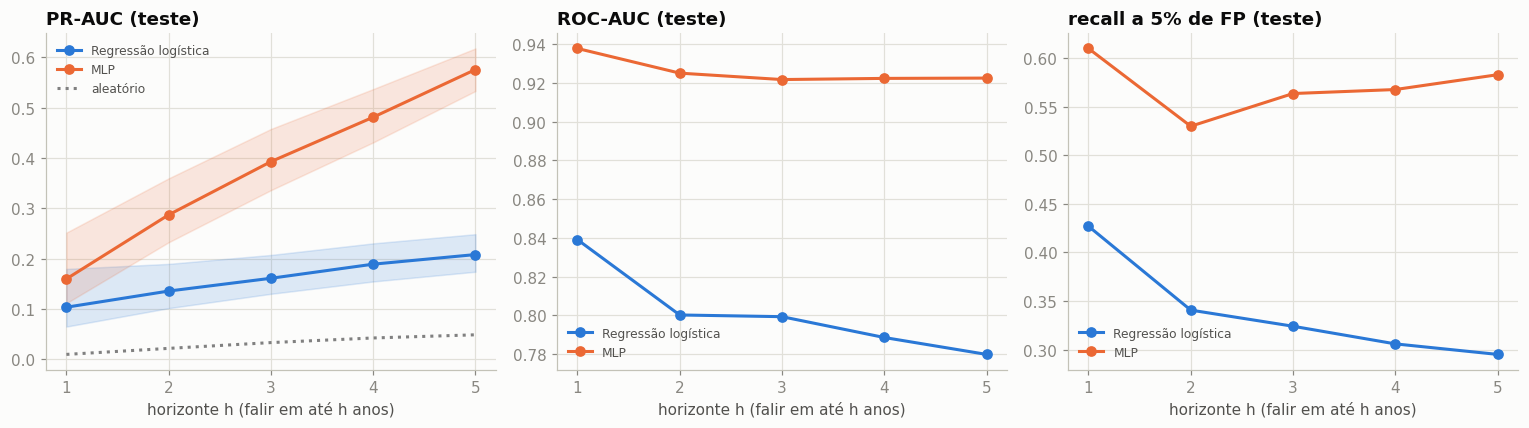

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for m in MODELOS:
    d = hor.loc[m]
    axes[0].plot(HORIZONTES, d['PR-AUC teste'], marker='o', color=COR[m], label=m)
    axes[0].fill_between(HORIZONTES, d['IC inf'], d['IC sup'], color=COR[m], alpha=0.15)
    axes[1].plot(HORIZONTES, d['ROC-AUC teste'], marker='o', color=COR[m], label=m)
    axes[2].plot(HORIZONTES, d['recall a 5% FP (teste)'], marker='o', color=COR[m], label=m)
axes[0].plot(HORIZONTES, hor.loc['MLP', 'prevalência teste'], ':', color='gray', label='aleatório')
for ax, t in zip(axes, ['PR-AUC (teste)', 'ROC-AUC (teste)', 'recall a 5% de FP (teste)']):
    ax.set(xlabel='horizonte h (falir em até h anos)', title=t)
    ax.set_xticks(HORIZONTES)
    ax.legend(fontsize=8)
plt.tight_layout()

## 2. Detecção por ano verdadeiro da falência
Limiar escolhido na validação (5% de falsos positivos entre as não falidas) e aplicado ao teste.

In [5]:
rec, media_cls = {}, {}
for m in MODELOS:
    s_v, s_t = escores(m)
    lim = np.quantile(s_v[y_tr == 0], 1 - FPR_ALVO)
    rec[m] = {f'faliu no ano {k}': np.mean(s_t[y_te == k] > lim) for k in HORIZONTES}
    rec[m]['taxa de FP (teste)'] = np.mean(s_t[y_te == 0] > lim)
    media_cls[m] = {NOME_CLASSE[k]: s_t[y_te == k].mean() for k in CLASSES}
rec = pd.DataFrame(rec).T
media_cls = pd.DataFrame(media_cls).T
print('Recall no teste por ano verdadeiro da falência (limiar da validação com 5% de FP):')
display(rec.round(3))
print('Escore médio de "faliu" no teste, por classe verdadeira:')
media_cls.round(3)

Recall no teste por ano verdadeiro da falência (limiar da validação com 5% de FP):


,faliu no ano 1,faliu no ano 2,faliu no ano 3,faliu no ano 4,faliu no ano 5,taxa de FP (teste)
Regressão logística,0.451,0.282,0.273,0.228,0.222,0.055
MLP,0.659,0.573,0.566,0.532,0.593,0.048


Escore médio de "faliu" no teste, por classe verdadeira:


,não faliu,faliu no ano 1,faliu no ano 2,faliu no ano 3,faliu no ano 4,faliu no ano 5
Regressão logística,0.046,0.157,0.117,0.112,0.106,0.104
MLP,0.035,0.347,0.333,0.351,0.338,0.380


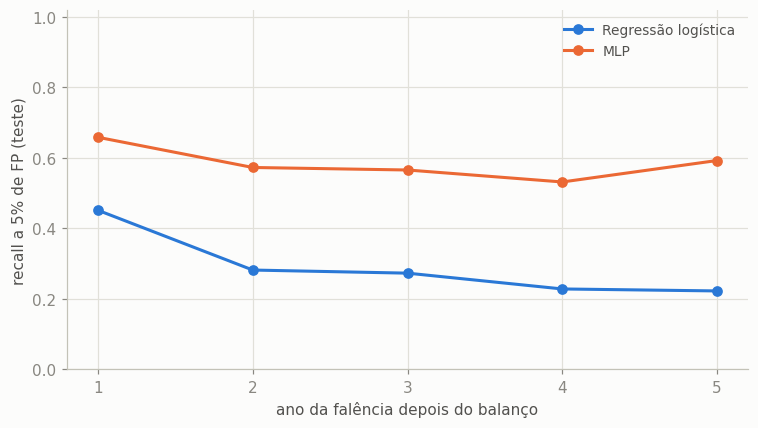

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for m in MODELOS:
    ax.plot(HORIZONTES, rec.loc[m, [f'faliu no ano {k}' for k in HORIZONTES]].values, marker='o', color=COR[m], label=m)
ax.set(xlabel='ano da falência depois do balanço', ylabel='recall a 5% de FP (teste)', ylim=(0, 1.02))
ax.set_xticks(HORIZONTES)
ax.legend(fontsize=9)
plt.tight_layout()

## 3. Taxa prevista por arquivo
Para cada arquivo, taxa de falência observada no teste e probabilidade média prevista de "faliu".
Um modelo sem informação de tempo tende a prever a mesma taxa para todos os arquivos, embora a taxa real vá de
3,9% (1year) a 7,0% (5year).

In [7]:
cal = []
for k in range(1, 6):
    idx = te['arquivo'].values == k
    lin = {'arquivo': f'{k}year', 'horizonte': f'{6 - k} ano(s)', 'taxa observada': yb_te[idx].mean()}
    for m in MODELOS:
        s_t = escores(m)[1][idx]
        lin[f'{m}: média prevista'] = s_t.mean()
        lin[f'{m}: ROC-AUC no arquivo'] = roc_auc_score(yb_te[idx], s_t)
    cal.append(lin)
cal = pd.DataFrame(cal).set_index('arquivo')
cal.round(3).T

arquivo,1year,2year,3year,4year,5year
horizonte,5 ano(s),4 ano(s),3 ano(s),2 ano(s),1 ano(s)
taxa observada,0.038,0.039,0.046,0.054,0.071
Regressão logística: média prevista,0.04,0.05,0.053,0.052,0.051
Regressão logística: ROC-AUC no arquivo,0.752,0.73,0.783,0.761,0.864
MLP: média prevista,0.04,0.051,0.054,0.05,0.053
MLP: ROC-AUC no arquivo,0.93,0.907,0.903,0.924,0.954


## 4. Salvando


In [8]:
hor.to_csv('resultados/alerta_horizonte.csv', encoding='utf-8-sig')
rec.to_csv('resultados/vies_tempo_recall.csv', encoding='utf-8-sig')
media_cls.to_csv('resultados/vies_tempo_media_por_classe.csv', encoding='utf-8-sig')
cal.to_csv('resultados/vies_tempo_por_arquivo.csv', encoding='utf-8-sig')

## Conclusões

- **Alerta em até *h* anos** (soma de $P(y=1) + \dots + P(y=h)$, sem outro modelo): a MLP vence em todos os
  horizontes. PR-AUC no teste de 0,16 (até 1 ano) a 0,58 (até 5 anos), contra 0,10 a 0,21 da logística; os IC 95%
  não se sobrepõem a partir de 2 anos. A validação prevê bem o teste nos dois modelos.
- **Recall a 5% de falsos positivos** (limiar fixado na validação): a MLP detecta 53–66% das falências em cada ano
  verdadeiro, quase sem perder força com a distância (66% no ano 1, 59% no ano 5). A logística cai de 45% (ano 1) para
  22% (ano 5): ela só enxerga bem quem está perto de falir.
- **Viés de tempo:** a probabilidade média prevista fica perto da taxa observada em todos os arquivos (MLP 0,040–0,054
  contra 0,038–0,071); o único desvio maior é o `5year` (falência no ano seguinte), onde os dois modelos preveem
  ~0,05 para uma taxa de 0,071. A ROC-AUC da MLP fica entre 0,90 e 0,95 em todos os arquivos; não há um horizonte
  em que o modelo desmorone.
- **Limitações:** a mesma empresa pode estar em mais de um arquivo e no treino e no teste ao mesmo tempo (não há
  identificador), e as ativas são censuradas ("não faliram até agora"). Os números do teste podem ser um pouco
  otimistas por isso.